# Neural pitcher architectures on the shared per-start dataset

Predict a starter's **hits allowed, strikeouts, walks and earned runs** from historical
pitcher features and the opposing lineup. This notebook reads
`data/starts_dataset.csv.gz`, produced by `expanded_per_start_dataset.ipynb`.
Data collection and feature generation stay in the other notebook; this notebook trains neural models.

Use the team's split: **train 2021–2024, validate/select on 2025, final test 2026**.
`RUN_FINAL_TEST = False` keeps 2026 out of model evaluation by default. Run cells in order; setup resolves the project folder independently of the kernel directory. No separate download cache or alternate feature dataset is needed.

Lineups are original starters reconstructed from box scores, not timestamped posted-lineup
snapshots. Historical features are supplied by the shared dataset; the source notebook remains
unchanged. The validation experiments here do not establish final-test performance.

## 1. Local setup

Use the project's `.venv` Python environment as the Jupyter kernel. Dependencies are listed
in `requirements.txt`. The setup locates the repository from the working directory or its
parents and also checks `~/Desktop/Berkeley/ML-Grad-Project`. Set `PROJECT_ROOT` explicitly
if your clone is elsewhere. The resolved project and CSV paths are printed below.

The shared `baselines/data.py` loader supplies the team's feature names, BvP smoothing prior
and year splits. Importing it does not fit any baseline model. The existing local CSV is used
directly; no uploads or data regeneration are needed.

In [1]:
# %pip install -r requirements.txt

from pathlib import Path
import copy
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = None  # Set to Path("/path/to/ML-Grad-Project") for another clone.


def find_project_root(project_root=None):
    """Locate the repository independently of Jupyter's working directory."""
    if project_root is not None:
        candidates = [Path(project_root).expanduser().resolve()]
    else:
        cwd = Path.cwd().resolve()
        candidates = [
            cwd,
            *cwd.parents,
            cwd / "ML-Grad-Project",
            Path.home() / "Desktop" / "Berkeley" / "ML-Grad-Project",
        ]
    for candidate in candidates:
        if (candidate / "baselines" / "data.py").is_file() and (
            candidate / "baselines" / "eval.py"
        ).is_file():
            return candidate
    searched = "\n".join(str(path) for path in dict.fromkeys(candidates))
    raise FileNotFoundError(
        f"Cannot locate ML-Grad-Project from working directory {Path.cwd()}.\n"
        f"Set PROJECT_ROOT to your repository folder. Searched:\n{searched}"
    )


ROOT = find_project_root(PROJECT_ROOT)
DATA_PATH = ROOT / "data" / "starts_dataset.csv.gz"
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Repository found at {ROOT}, but the CSV is missing at {DATA_PATH}. "
        "Check PROJECT_ROOT or run expanded_per_start_dataset.ipynb in that repository."
    )
sys.path.insert(0, str(ROOT / "baselines"))
import data as team_data
from eval import TARGETS, evaluate

ARTIFACT_DIR = ROOT / "artifacts" / "neural_shared"
REPORT_DIR = ROOT / "reports" / "neural_shared"
for folder in [ARTIFACT_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RUN_FINAL_TEST = (
    False  # Enable once architectures/settings are frozen for final evaluation.
)
SEED = 42
SEEDS = [42, 43, 44]
MAX_EPOCHS = 80
PATIENCE = 12
BATCH_SIZE = 512
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-3
LABELS = dict(zip(TARGETS, ["Hits allowed", "Strikeouts", "Walks", "Earned runs"]))
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
pd.set_option("display.max_columns", 12)
print("Jupyter working directory:", Path.cwd())
print("Project folder:", ROOT)
print("Data:", DATA_PATH)
print("Final-test evaluation enabled:", RUN_FINAL_TEST)


Jupyter working directory: /Users/pliu/Desktop/Berkeley/ML-Grad-Project
Project folder: /Users/pliu/Desktop/Berkeley/ML-Grad-Project
Data: /Users/pliu/Desktop/Berkeley/ML-Grad-Project/data/starts_dataset.csv.gz
Final-test evaluation enabled: False


### BvP prior sweep controls

Edit the list below to choose the pseudo-at-bat strengths to compare. **Run All** retrains
every architecture with three seeds at each strength, then selects the strength and
architecture using 2025 validation MAE. The 2026 test remains disabled.

The initial `BVP_SHRINK = 100` is only the reference used by preprocessing checks. It does
**not** override the sweep winner. To test only lighter smoothing, use `[10, 30]`.

In [2]:
BVP_SHRINK_CANDIDATES = [10, 30, 100]  # Pseudo-at-bats; other priors are unchanged.
BVP_SHRINK = (
    100  # Reference for preprocessing checks; training selects the final value.
)

print("BvP prior strengths to train:", BVP_SHRINK_CANDIDATES)


BvP prior strengths to train: [10, 30, 100]


## 2. Load and inspect the shared data

The CSV has one row per starting-pitcher appearance, four targets and statistics for all nine
opposing batting slots. The team loader supplies a 100-pseudo-at-bat BvP reference. This notebook
then recomputes **only BvP averages** from historical hits/at-bats with strengths 10, 30 and 100.
The league BvP mean is fixed using 2021–2024 training rows only, matching the team calculation.
General pitcher/batter priors and the shared data/code are unchanged.

A missing raw BvP average means no history, not zero ability. Even with lighter smoothing,
zero-history pairs still receive the league prior. Only identifiers/dates are read for the
all-season coverage table; 2026 is excluded from training/evaluation by default.

In [2]:
coverage = (
    pd.read_csv(DATA_PATH, usecols=["game_pk", "date", "season"])
    .groupby("season")
    .agg(
        pitcher_games=("game_pk", "size"),
        games=("game_pk", "nunique"),
        first=("date", "min"),
        last=("date", "max"),
    )
)
display(coverage)
team_splits = team_data.load_splits(DATA_PATH, include_test=RUN_FINAL_TEST)
frames = {"train": team_splits["train"].copy(), "validation": team_splits["val"].copy()}
if RUN_FINAL_TEST:
    frames["test"] = team_splits["test"].copy()
assert team_data.TRAIN_SEASONS == [2021, 2022, 2023, 2024]
assert team_data.VAL_SEASON == 2025 and team_data.TEST_SEASON == 2026
assert all(not frame.empty for frame in frames.values())
assert frames["train"].date.max() < frames["validation"].date.min()
if RUN_FINAL_TEST:
    assert frames["validation"].date.max() < frames["test"].date.min()
else:
    assert all(not frame.season.eq(2026).any() for frame in frames.values())

split_summary = pd.DataFrame(
    {
        split: {
            "n": len(frame),
            "first": frame.date.min().strftime("%Y-%m-%d"),
            "last": frame.date.max().strftime("%Y-%m-%d"),
        }
        for split, frame in frames.items()
    }
).T
display(split_summary)
print("BvP features available:", team_data.has_bvp(frames["train"]))


,pitcher_games,games,first,last
season,,,,
2021,4858,2429,2021-04-01,2021-10-03
2022,4860,2430,2022-04-07,2022-10-05
2023,4860,2430,2023-03-30,2023-10-02
2024,4858,2429,2024-03-20,2024-09-30
2025,4860,2430,2025-03-18,2025-09-28
2026,4858,2429,2026-03-25,2026-09-27


,n,first,last
train,19436,2021-04-01,2024-09-30
validation,4860,2025-03-18,2025-09-28


BvP features available: True


### Guard against same-day pitcher-history leakage

The shared source's rolling-365-day and BvP windows exclude the current date. However,
last-five and season-to-date pitcher features shift by **row**, so a second start recorded
on the same date could contain that day's first outcome. For such rows only, reuse the first
row's pitcher lags, season-to-date averages and rest value for that pitcher/date. This preserves
both rows while freezing those features for the date. The CSV and teammate notebooks are
not modified. The correction count below makes this difference from an unadjusted load visible.

This does not reconstruct historical publication times, suspended-game availability or later
scoring corrections; full point-in-time certification still requires source snapshots.

In [3]:
def freeze_same_day_history(frame):
    frame = frame.sort_values(["date", "game_pk", "pitcher_id"]).copy()
    key = ["pitcher_id", "date"]
    lag_columns = [c for c in frame if c.startswith(("p_l5_", "p_std_"))] + [
        "p_rest_days"
    ]
    repeated = frame.duplicated(key, keep="first")
    frame[lag_columns] = frame.groupby(key)[lag_columns].transform("first")
    return frame.reset_index(drop=True), int(repeated.sum())


same_day_corrections = {}
for split, frame in frames.items():
    frames[split], same_day_corrections[split] = freeze_same_day_history(frame)
print("Same-date extra starts frozen:", same_day_corrections)


Same-date extra starts frozen: {'train': 1, 'validation': 0}


## 3. Select features and fit training-only scalers

- **Pitcher/context:** the shared `p_` historical features plus home status (21 values).
- **Each batter:** PA, K rate, BB rate, OBP, ISO, platoon advantage and left-handed indicator,
  plus historical BvP at-bats and shrunk BvP average (9 values per slot).
- Apply `log1p` to PA and BvP at-bat counts before scaling. Fit one pitcher scaler and a
  single shared batter scaler using training rows only. All architectures receive those
  same tensors; IDs, dates and targets never enter model inputs.

The aggregate control averages the nine transformed batter vectors. Its mean of individually
shrunk BvP features is a model input summary, **not** the source's at-bat-weighted lineup
batting average. This isolates pooling while keeping the underlying per-player inputs fixed.

In [4]:
pitcher_columns = [c for c in frames["train"] if c.startswith("p_")] + ["home"]
batter_columns = team_data.batter_columns(include_bvp=True)
BATTER_DIM = len(batter_columns[0])
PITCHER_DIM = len(pitcher_columns)
input_columns = pitcher_columns + [c for columns in batter_columns for c in columns]
assert set(input_columns).isdisjoint(
    TARGETS + ["game_pk", "pitcher_id", "date", "season"]
)
for frame in frames.values():
    assert not frame.duplicated(["game_pk", "pitcher_id"]).any()
    assert frame[input_columns + TARGETS].notna().all().all()
    assert np.isfinite(frame[input_columns + TARGETS].to_numpy(float)).all()
    assert frame[TARGETS].ge(0).all().all()
    for slot in range(1, 10):
        assert frame[f"b{slot}_bvp_ab"].ge(frame[f"b{slot}_bvp_h"]).all()


def raw_inputs(frame, pitcher_cols, batter_cols):
    pitcher = frame[pitcher_cols].to_numpy(float)
    batters = np.stack(
        [frame[columns].to_numpy(float) for columns in batter_cols], axis=1
    )
    # Feature order comes directly from team_data.batter_columns().
    for i, column in enumerate(batter_cols[0]):
        if column.endswith(("_pa", "_bvp_ab")):
            if (batters[:, :, i] < 0).any():
                raise ValueError("Historical exposure counts cannot be negative")
            batters[:, :, i] = np.log1p(batters[:, :, i])
    return pitcher, batters


def transform_inputs(frame, fitted_scalers, pitcher_cols, batter_cols):
    pitcher, batters = raw_inputs(frame, pitcher_cols, batter_cols)
    dim = len(batter_cols[0])
    pitcher = fitted_scalers["pitcher"].transform(pitcher)
    batters = (
        fitted_scalers["batter"].transform(batters.reshape(-1, dim)).reshape(-1, 9, dim)
    )
    if not np.isfinite(pitcher).all() or not np.isfinite(batters).all():
        raise ValueError("Non-finite model inputs")
    return torch.tensor(pitcher, dtype=torch.float32), torch.tensor(
        batters, dtype=torch.float32
    )


def apply_bvp_smoothing(frame, prior, strength):
    """Recompute BvP from historical counts; never use current-game target columns."""
    if not np.isfinite(strength) or strength <= 0:
        raise ValueError(
            "BvP strength must be positive; zero-history pairs need a fallback"
        )
    result = frame.copy()
    for prefix in ["lu_bvp"] + [f"b{slot}_bvp" for slot in range(1, 10)]:
        hits, at_bats = result[f"{prefix}_h"], result[f"{prefix}_ab"]
        result[f"{prefix}_avg_shrunk"] = (hits + strength * prior) / (
            at_bats + strength
        )
    return result


bvp_prior = float(frames["train"].lu_bvp_h.sum() / frames["train"].lu_bvp_ab.sum())


def prepare_inputs(source_frames, strength):
    adjusted = {
        split: apply_bvp_smoothing(frame, bvp_prior, strength)
        for split, frame in source_frames.items()
    }
    pitcher, batters = raw_inputs(adjusted["train"], pitcher_columns, batter_columns)
    fitted_scalers = {
        "pitcher": StandardScaler().fit(pitcher),
        "batter": StandardScaler().fit(batters.reshape(-1, BATTER_DIM)),
    }
    values = {
        split: transform_inputs(frame, fitted_scalers, pitcher_columns, batter_columns)
        for split, frame in adjusted.items()
    }
    return adjusted, fitted_scalers, values


source_frames = {split: frame.copy() for split, frame in frames.items()}
frames, scalers, inputs = prepare_inputs(source_frames, BVP_SHRINK)
Y = {split: frame[TARGETS].to_numpy(float) for split, frame in frames.items()}
train_pitcher, train_batters = raw_inputs(
    frames["train"], pitcher_columns, batter_columns
)
assert np.allclose(scalers["pitcher"].mean_, train_pitcher.mean(axis=0))
assert np.allclose(
    scalers["batter"].mean_, train_batters.reshape(-1, BATTER_DIM).mean(axis=0)
)
print("Pitcher inputs:", PITCHER_DIM, "Batter inputs:", (9, BATTER_DIM))
print("Training-only BvP prior:", bvp_prior)
display(
    pd.DataFrame(
        {"batter_statistic": team_data.BATTER_FEATS + team_data.BVP_BATTER_FEATS}
    )
)


Pitcher inputs: 21 Batter inputs: (9, 9)
Training-only BvP prior: 0.2570873763521338


,batter_statistic
0,pa
1,k_rate
2,bb_rate
3,obp
4,iso
5,platoon_adv
6,bats_L
7,bvp_ab
8,bvp_avg_shrunk


### Check preprocessing boundaries

A synthetic duplicate-date example verifies that changes in a later row's lag values do not
change its frozen input. Transforming modified validation data must not refit either scaler.
These checks verify this notebook's boundaries, not every upstream feature's provenance.

In [5]:
probe = frames["train"].iloc[[0, 0]].copy().reset_index(drop=True)
probe.loc[1, "game_pk"] = probe.loc[0, "game_pk"] + 1
probe.loc[1, "p_l5_h"] = 999
frozen, count = freeze_same_day_history(probe)
assert count == 1 and frozen.loc[0, "p_l5_h"] == frozen.loc[1, "p_l5_h"]
means_before = {name: scaler.mean_.copy() for name, scaler in scalers.items()}
probe = frames["validation"].head(2).copy()
probe[pitcher_columns] += 1
transform_inputs(probe, scalers, pitcher_columns, batter_columns)
assert all(
    np.array_equal(scalers[name].mean_, mean) for name, mean in means_before.items()
)
assert scalers["pitcher"].n_samples_seen_ == len(frames["train"])
assert scalers["batter"].n_samples_seen_ == 9 * len(frames["train"])
print("Date-freezing and training-only scaler checks passed.")


# Strength 100 exactly reproduces the team's reference feature; other columns never change.
reference = apply_bvp_smoothing(source_frames["validation"], bvp_prior, 100)
for slot in range(1, 10):
    column = f"b{slot}_bvp_avg_shrunk"
    assert np.allclose(reference[column], source_frames["validation"][column])
probe = source_frames["validation"].head(2).copy()
probe.loc[probe.index[0], ["b1_bvp_h", "b1_bvp_ab"]] = [0, 0]
probe.loc[probe.index[1], ["b1_bvp_h", "b1_bvp_ab"]] = [1, 2]
light = apply_bvp_smoothing(probe, bvp_prior, 10)
heavy = apply_bvp_smoothing(probe, bvp_prior, 100)
assert np.isclose(light.iloc[0].b1_bvp_avg_shrunk, bvp_prior)
assert abs(light.iloc[1].b1_bvp_avg_shrunk - 0.5) < abs(
    heavy.iloc[1].b1_bvp_avg_shrunk - 0.5
)
untouched = [c for c in probe if not c.endswith("_bvp_avg_shrunk")]
assert light[untouched].equals(probe[untouched])
changed_targets = probe.copy()
changed_targets[TARGETS] = 999
assert np.allclose(
    apply_bvp_smoothing(changed_targets, bvp_prior, 10)["b1_bvp_avg_shrunk"],
    light["b1_bvp_avg_shrunk"],
)
print("BvP strength, zero-history fallback and target-isolation checks passed.")


Date-freezing and training-only scaler checks passed.
BvP strength, zero-history fallback and target-isolation checks passed.


## 4. Neural architectures

| Architecture | Processing |
|---|---|
| Aggregate MLP | Pitcher + mean batter vector; hidden 64 → 32 |
| Flat MLP | Pitcher + nine ordered batter vectors; hidden 64 → 32 |
| Deep MLP | Same flattened inputs; hidden 128 → 64 → 32 |
| Matchup encoder | Shared nonlinear pitcher–batter encoding, then mean of learned representations |
| Pitcher attention | Same matchup encoder; pitcher query weights the nine encoded matchups |

All use four Softplus outputs, MSE loss and the same optimizer/stopping settings. A batting-slot
coordinate preserves order in the two shared-encoder models. They pool **after** nonlinear
interaction encoding, whereas the aggregate control pools before its network. 

In [6]:
ARCHITECTURES = [
    "aggregate_mlp",
    "flat_mlp",
    "deep_mlp",
    "matchup_encoder",
    "pitcher_attention",
]


def dense_layers(in_dim, widths, out_dim):
    layers = []
    for width in widths:
        layers.extend([nn.Linear(in_dim, width), nn.ReLU()])
        in_dim = width
    return nn.Sequential(*layers, nn.Linear(in_dim, out_dim))


class FlatMLP(nn.Module):
    def __init__(self, aggregate=False, deep=False):
        super().__init__()
        self.aggregate = aggregate
        in_dim = PITCHER_DIM + BATTER_DIM * (1 if aggregate else 9)
        self.network = dense_layers(in_dim, [128, 64, 32] if deep else [64, 32], 4)

    def forward(self, pitcher, batters):
        lineup = batters.mean(dim=1) if self.aggregate else batters.flatten(1)
        return nn.functional.softplus(
            self.network(torch.cat([pitcher, lineup], dim=-1))
        )


class MatchupNetwork(nn.Module):
    def __init__(self, attention=False):
        super().__init__()
        self.pitcher_encoder = dense_layers(PITCHER_DIM, [32], 32)
        self.matchup_encoder = dense_layers(32 + BATTER_DIM + 1, [32], 32)
        self.attention = (
            nn.MultiheadAttention(32, 4, batch_first=True) if attention else None
        )
        self.head = dense_layers(64, [32], 4)
        self.register_buffer("slots", torch.linspace(-1, 1, 9).reshape(1, 9, 1))

    def forward(self, pitcher, batters):
        pitcher_state = self.pitcher_encoder(pitcher)
        repeated_pitcher = pitcher_state[:, None, :].expand(-1, 9, -1)
        slots = self.slots.expand(len(pitcher), -1, -1)
        pairs = self.matchup_encoder(
            torch.cat([repeated_pitcher, batters, slots], dim=-1)
        )
        if self.attention is None:
            lineup_state = pairs.mean(dim=1)
        else:
            attended, _ = self.attention(
                pitcher_state[:, None, :], pairs, pairs, need_weights=False
            )
            lineup_state = attended[:, 0, :]
        return nn.functional.softplus(
            self.head(torch.cat([pitcher_state, lineup_state], dim=-1))
        )


def make_model(name):
    if name in ["aggregate_mlp", "flat_mlp", "deep_mlp"]:
        return FlatMLP(aggregate=name == "aggregate_mlp", deep=name == "deep_mlp")
    if name in ["matchup_encoder", "pitcher_attention"]:
        return MatchupNetwork(attention=name == "pitcher_attention")
    raise ValueError(f"Unknown architecture: {name}")


parameter_counts = {
    name: sum(p.numel() for p in make_model(name).parameters())
    for name in ARCHITECTURES
}
display(pd.Series(parameter_counts, name="Parameters").to_frame())


,Parameters
aggregate_mlp,4196
flat_mlp,8804
deep_mlp,23652
matchup_encoder,6404
pitcher_attention,10628


### Architecture checks

The aggregate control must ignore changes that preserve lineup means. Shared encoders must
respond to changed batter distributions and allow gradients to reach all nine batter inputs.

In [7]:
torch.manual_seed(SEED)
p = torch.randn(3, PITCHER_DIM)
b = torch.randn(3, 9, BATTER_DIM)
changed = b.clone()
changed[:, 0] += 2
changed[:, 1] -= 2
aggregate = make_model("aggregate_mlp").eval()
assert torch.allclose(aggregate(p, b), aggregate(p, changed), atol=1e-6)
for name in ARCHITECTURES:
    model = make_model(name).eval()
    prediction = model(p, b)
    assert prediction.shape == (3, 4) and torch.isfinite(prediction).all()
    assert (prediction > 0).all()
    if name in ["matchup_encoder", "pitcher_attention"]:
        assert not torch.allclose(prediction, model(p, changed), atol=1e-6)
        pitcher = p.clone().requires_grad_()
        batters = b.clone().requires_grad_()
        model(pitcher, batters).sum().backward()
        assert pitcher.grad.abs().sum() > 0
        assert (batters.grad.abs().sum(dim=(0, 2)) > 0).all()
print("Architecture input, output and gradient checks passed.")


Architecture input, output and gradient checks passed.


## 5. Compare BvP smoothing strengths and train architectures

Compare **10, 30 and 100 pseudo-at-bats**, each with the same five architectures, three seeds,
optimizer, 80-epoch limit and 12-epoch validation patience. This is 45 fresh training runs.
Keep general-player smoothing, historical counts and source rows fixed; refit training-only
scalers for each strength because the BvP feature distribution changes.

Choose the **strength and architecture jointly by 2025 ensemble validation MAE**, averaged
across the four targets. Smaller strength gives actual matchup history more weight, but may
also amplify small-sample noise. Include 100 as a control rather than assuming lighter wins.
The mean itself is unchanged and fitted only on training seasons. 2026 is not involved.

For two historical at-bats, the prior contributes 83.3% at strength 10, 93.8% at 30, and 98.0%
at 100. At zero at-bats it always contributes 100%. These are input weights, not prediction weights.

In [8]:
@torch.no_grad()
def model_predict(model, values):
    model.eval()
    return model(*values).cpu().numpy()


def fit_model(
    name, seed, train_values, train_targets, validation_values, validation_targets
):
    torch.manual_seed(seed)
    model = make_model(name)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    dataset = TensorDataset(
        *train_values, torch.tensor(train_targets, dtype=torch.float32)
    )
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_epoch, stale = float("inf"), 0, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for pitcher, batters, target in loader:
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(pitcher, batters), target)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(target)
        score = mean_absolute_error(
            validation_targets, model_predict(model, validation_values)
        )
        history.append(
            {
                "architecture": name,
                "seed": seed,
                "epoch": epoch,
                "train_mse": total_loss / len(dataset),
                "validation_mae": float(score),
            }
        )
        if score < best_score - 1e-4:
            best_score, best_epoch, stale = float(score), epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_state)
    model.eval()
    return (
        model,
        {
            "architecture": name,
            "seed": seed,
            "best_epoch": best_epoch,
            "epochs_run": epoch,
            "validation_mae": best_score,
        },
        history,
    )


In [9]:
experiments, sweep_rows, sweep_runs, sweep_curves = {}, [], [], []
for strength in BVP_SHRINK_CANDIDATES:
    candidate_frames, candidate_scalers, candidate_inputs = prepare_inputs(
        source_frames, strength
    )
    candidate_models = {}
    for name in ARCHITECTURES:
        candidate_models[name] = []
        for seed in SEEDS:
            model, summary, curve = fit_model(
                name,
                seed,
                candidate_inputs["train"],
                Y["train"],
                candidate_inputs["validation"],
                Y["validation"],
            )
            candidate_models[name].append(model)
            sweep_runs.append({"bvp_shrink": strength, **summary})
            sweep_curves.extend({"bvp_shrink": strength, **row} for row in curve)
        prediction = np.mean(
            [
                model_predict(model, candidate_inputs["validation"])
                for model in candidate_models[name]
            ],
            axis=0,
        )
        errors = np.abs(prediction - Y["validation"]).mean(axis=0)
        sweep_rows.append(
            {
                "bvp_shrink": strength,
                "architecture": name,
                "validation_mae": float(errors.mean()),
                **{
                    f"{target}_mae": float(value)
                    for target, value in zip(TARGETS, errors)
                },
            }
        )
        print(
            f"BvP {strength}, {name}: three-seed validation MAE {errors.mean():.4f}",
            flush=True,
        )
    experiments[strength] = {
        "frames": candidate_frames,
        "scalers": candidate_scalers,
        "inputs": candidate_inputs,
        "models": candidate_models,
    }

sweep_table = pd.DataFrame(sweep_rows)
winner = sweep_table.loc[sweep_table.validation_mae.idxmin()]
BVP_SHRINK, selected_name = int(winner.bvp_shrink), winner.architecture
chosen = experiments[BVP_SHRINK]
frames, scalers, inputs, models = [
    chosen[key] for key in ["frames", "scalers", "inputs", "models"]
]
run_summary = [
    {k: v for k, v in row.items() if k != "bvp_shrink"}
    for row in sweep_runs
    if row["bvp_shrink"] == BVP_SHRINK
]
learning_curves = [row for row in sweep_curves if row["bvp_shrink"] == BVP_SHRINK]
validation_predictions = {
    name: np.mean(
        [model_predict(model, inputs["validation"]) for model in fitted], axis=0
    )
    for name, fitted in models.items()
}
validation_scores = {
    name: float(mean_absolute_error(Y["validation"], prediction))
    for name, prediction in validation_predictions.items()
}
validation_summary = (
    pd.DataFrame(run_summary)
    .groupby("architecture")
    .agg(
        seed_mae_mean=("validation_mae", "mean"),
        seed_mae_std=("validation_mae", "std"),
        mean_best_epoch=("best_epoch", "mean"),
    )
)
validation_summary["ensemble_mae"] = pd.Series(validation_scores)
validation_summary["parameters_per_model"] = pd.Series(parameter_counts)
display(sweep_table.sort_values("validation_mae").round(5))
display(validation_summary.sort_values("ensemble_mae").round(4))
print(f"Selected on 2025 only: {selected_name}, BvP strength {BVP_SHRINK}")
# Keep only the selected strength's models/tensors after recording the sweep.
del (
    experiments,
    chosen,
    candidate_models,
    candidate_frames,
    candidate_scalers,
    candidate_inputs,
)


BvP 10, aggregate_mlp: three-seed validation MAE 1.5099


BvP 10, flat_mlp: three-seed validation MAE 1.5269


BvP 10, deep_mlp: three-seed validation MAE 1.5286


BvP 10, matchup_encoder: three-seed validation MAE 1.5077


BvP 10, pitcher_attention: three-seed validation MAE 1.5094


BvP 30, aggregate_mlp: three-seed validation MAE 1.5102


... (8 outputs left out)

BvP 100, pitcher_attention: three-seed validation MAE 1.5071


,bvp_shrink,architecture,validation_mae,hits_mae,strikeouts_mae,walks_mae,earned_runs_mae
14,100,pitcher_attention,1.50713,1.70197,1.75467,1.01600,1.55588
9,30,pitcher_attention,1.50760,1.70216,1.75465,1.01550,1.55811
3,10,matchup_encoder,1.50767,1.70315,1.75579,1.01388,1.55786
8,30,matchup_encoder,1.50773,1.70306,1.75581,1.01392,1.55815
13,100,matchup_encoder,1.50777,1.70317,1.75594,1.01443,1.55753
4,10,pitcher_attention,1.50937,1.70288,1.75523,1.01888,1.56049
0,10,aggregate_mlp,1.50987,1.70889,1.76026,1.01395,1.55638
10,100,aggregate_mlp,1.51008,1.70912,1.76055,1.01416,1.55647
5,30,aggregate_mlp,1.51016,1.70937,1.76069,1.01437,1.55622
6,30,flat_mlp,1.52681,1.73843,1.77764,1.02265,1.56851


,seed_mae_mean,seed_mae_std,mean_best_epoch,ensemble_mae,parameters_per_model
architecture,,,,,
pitcher_attention,1.5102,0.0009,40.0000,1.5071,10628
matchup_encoder,1.5098,0.0014,34.6667,1.5078,6404
aggregate_mlp,1.5134,0.0012,37.3333,1.5101,4196
flat_mlp,1.5341,0.0005,17.6667,1.5272,8804
deep_mlp,1.5352,0.0014,11.0000,1.5296,23652


Selected on 2025 only: pitcher_attention, BvP strength 100


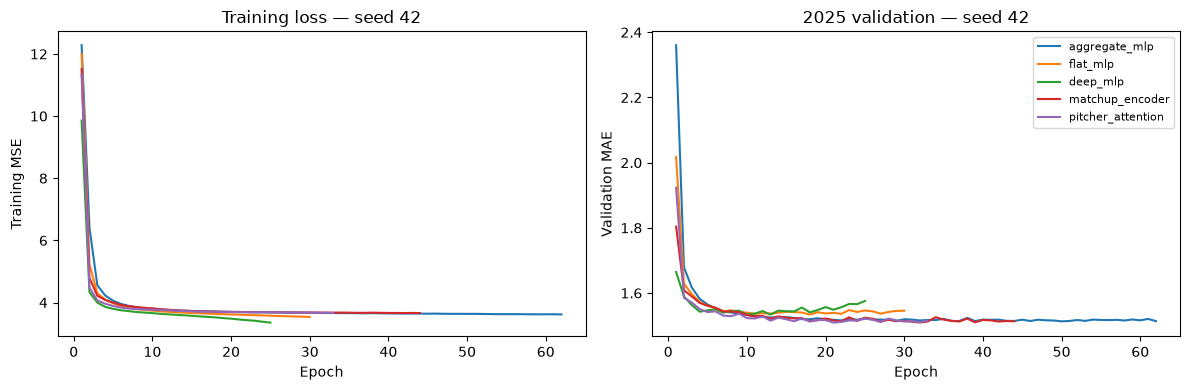

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
curves = pd.DataFrame(learning_curves)
for name, group in curves.groupby("architecture", sort=False):
    # Show seed 42 to avoid averaging curves with different stopping lengths.
    curve = group[group["seed"] == SEEDS[0]]
    axes[0].plot(curve["epoch"], curve["train_mse"], label=name)
    axes[1].plot(curve["epoch"], curve["validation_mae"], label=name)
axes[0].set(xlabel="Epoch", ylabel="Training MSE", title="Training loss — seed 42")
axes[1].set(xlabel="Epoch", ylabel="Validation MAE", title="2025 validation — seed 42")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 6. Evaluate architectures

Use the team's `baselines/eval.py` for per-target MAE/RMSE and add R². With default settings,
the tables and charts below describe **2025 validation**, which is also used for stopping and
selection; these are not unbiased final-test estimates. If `RUN_FINAL_TEST` is enabled, report
2026 separately after the same 2025-based selection. Constant training means and the shared
pitcher season-to-date averages are reference predictions only; no other models are fitted.

Validation


,model,target,mae,rmse,r2
0,aggregate_mlp,Hits allowed,1.7091,2.1284,0.0820
1,aggregate_mlp,Strikeouts,1.7606,2.2253,0.1886
2,aggregate_mlp,Walks,1.0142,1.2582,0.0470
3,aggregate_mlp,Earned runs,1.5565,1.9505,0.0338
4,flat_mlp,Hits allowed,1.7379,2.1657,0.0495
5,flat_mlp,Strikeouts,1.7793,2.2421,0.1763
6,flat_mlp,Walks,1.0232,1.2621,0.0410
7,flat_mlp,Earned runs,1.5684,1.9585,0.0259
8,deep_mlp,Hits allowed,1.7439,2.1672,0.0482
9,deep_mlp,Strikeouts,1.7804,2.2403,0.1777


model,aggregate_mlp,deep_mlp,flat_mlp,matchup_encoder,pitcher_attention,pitcher_season_average,train_mean
target,,,,,,,
Earned runs,1.5565,1.5672,1.5684,1.5575,1.5559,1.6605,1.6130
Hits allowed,1.7091,1.7439,1.7379,1.7032,1.7020,1.8417,1.7654
Strikeouts,1.7606,1.7804,1.7793,1.7559,1.7547,1.9067,1.9792
Walks,1.0142,1.0268,1.0232,1.0144,1.0160,1.0840,1.0599


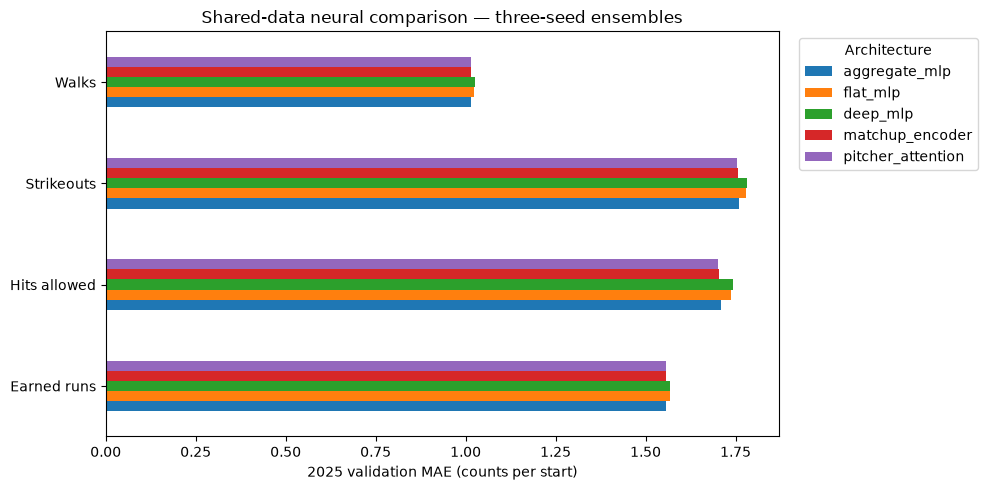

In [11]:
def metrics(y, pred):
    table = evaluate(y, pred, targets=TARGETS).rename(
        columns={"MAE": "mae", "RMSE": "rmse"}
    )
    table["r2"] = [r2_score(y[:, i], pred[:, i]) for i in range(len(TARGETS))]
    return table.to_dict(orient="index")


evaluation_splits = [split for split in frames if split != "train"]
preds = {
    name: {
        split: (
            validation_predictions[name]
            if split == "validation"
            else np.mean(
                [model_predict(model, inputs[split]) for model in fitted], axis=0
            )
        )
        for split in evaluation_splits
    }
    for name, fitted in models.items()
}
preds["train_mean"] = {
    split: np.tile(Y["train"].mean(axis=0), (len(Y[split]), 1))
    for split in evaluation_splits
}
preds["pitcher_season_average"] = {
    split: frames[split][["p_std_h", "p_std_k", "p_std_bb", "p_std_er"]].to_numpy(float)
    for split in evaluation_splits
}
metric_table = pd.DataFrame(
    [
        {"split": split, "model": name, "target": LABELS[target], **values}
        for name, splits in preds.items()
        for split, prediction in splits.items()
        for target, values in metrics(Y[split], prediction).items()
    ]
)
for split in evaluation_splits:
    print(split.title())
    display(metric_table[metric_table["split"] == split].drop(columns="split").round(4))

report_split = "test" if RUN_FINAL_TEST else "validation"
report_year = team_data.TEST_SEASON if RUN_FINAL_TEST else team_data.VAL_SEASON
report_mae = metric_table[metric_table["split"] == report_split].pivot(
    index="target", columns="model", values="mae"
)
display(report_mae.round(4))
ax = report_mae[ARCHITECTURES].plot.barh(figsize=(10, 5))
ax.set(
    xlabel=f"{report_year} {report_split} MAE (counts per start)",
    ylabel="",
    title="Shared-data neural comparison — three-seed ensembles",
)
ax.legend(title="Architecture", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Seed sensitivity and paired comparisons

Report individual-seed MAE variability and paired date-bootstrap intervals. Negative MAE
differences favor the first architecture. With final evaluation disabled, the intervals are
**descriptive validation comparisons** after selection, not confirmatory significance tests.
They do not fully capture serial/player dependence or correct for multiple comparisons.

In [12]:
seed_metrics = []
for name, fitted in models.items():
    for seed, model in zip(SEEDS, fitted):
        for target, values in metrics(
            Y[report_split], model_predict(model, inputs[report_split])
        ).items():
            seed_metrics.append(
                {"architecture": name, "seed": seed, "target": LABELS[target], **values}
            )
seed_table = pd.DataFrame(seed_metrics)
display(
    seed_table.groupby(["architecture", "target"])["mae"].agg(["mean", "std"]).round(4)
)

comparisons = [
    (name, "aggregate_mlp") for name in ARCHITECTURES if name != "aggregate_mlp"
]
comparisons += [(name, "flat_mlp") for name in ["matchup_encoder", "pitcher_attention"]]
rng = np.random.default_rng(SEED)
intervals = []
for name, reference in comparisons:
    difference = abs(preds[name][report_split] - Y[report_split]) - abs(
        preds[reference][report_split] - Y[report_split]
    )
    daily = pd.DataFrame(difference, columns=TARGETS).assign(
        date=frames[report_split]["date"].to_numpy()
    )
    sums = daily.groupby("date")[TARGETS].sum().to_numpy()
    sizes = daily.groupby("date").size().to_numpy()
    sampled = rng.integers(0, len(sizes), size=(2000, len(sizes)))
    bootstrap = sums[sampled].sum(axis=1) / sizes[sampled].sum(axis=1)[:, None]
    for i, target in enumerate(TARGETS):
        low, high = np.quantile(bootstrap[:, i], [0.025, 0.975])
        intervals.append(
            {
                "architecture": name,
                "reference": reference,
                "target": LABELS[target],
                "MAE difference": difference[:, i].mean(),
                "95% low": low,
                "95% high": high,
            }
        )
interval_table = pd.DataFrame(intervals)
display(interval_table.round(4))


mean     std
architecture      target                      
aggregate_mlp     Earned runs   1.5582  0.0034
                  Hits allowed  1.7138  0.0025
                  Strikeouts    1.7662  0.0045
                  Walks         1.0156  0.0003
deep_mlp          Earned runs   1.5695  0.0013
                  Hits allowed  1.7517  0.0028
                  Strikeouts    1.7909  0.0052
                  Walks         1.0288  0.0049
flat_mlp          Earned runs   1.5720  0.0023
                  Hits allowed  1.7482  0.0025
                  Strikeouts    1.7903  0.0013
                  Walks         1.0260  0.0021
matchup_encoder   Earned runs   1.5584  0.0047
                  Hits allowed  1.7062  0.0026
                  Strikeouts    1.7590  0.0019
                  Walks         1.0156  0.0004
pitcher_attention Earned runs   1.5576  0.0045
                  Hits allowed  1.7061  0.0049
                  Strikeouts    1.7592  0.0066
                  Walks         1.0181  0.0031

,architecture,reference,target,MAE difference,95% low,95% high
0,flat_mlp,aggregate_mlp,Hits allowed,0.0288,0.0183,0.0387
1,flat_mlp,aggregate_mlp,Strikeouts,0.0187,0.0088,0.0281
2,flat_mlp,aggregate_mlp,Walks,0.0091,0.0043,0.0138
3,flat_mlp,aggregate_mlp,Earned runs,0.0119,0.0049,0.0187
4,deep_mlp,aggregate_mlp,Hits allowed,0.0348,0.0236,0.0456
5,deep_mlp,aggregate_mlp,Strikeouts,0.0198,0.0102,0.0298
6,deep_mlp,aggregate_mlp,Walks,0.0126,0.0078,0.0176
7,deep_mlp,aggregate_mlp,Earned runs,0.0107,0.0039,0.0176
8,matchup_encoder,aggregate_mlp,Hits allowed,-0.0059,-0.0122,0.0001
9,matchup_encoder,aggregate_mlp,Strikeouts,-0.0046,-0.0096,0.0002


## 7. Save this shared-data experiment

New checkpoints and reports live under `artifacts/neural_shared/` and `reports/neural_shared/`.
Save the feature order, scalers, source fingerprint, BvP prior, year splits and training choices.
The saved model's weights were fitted through 2024 and selected using 2025 labels. Its
performance on 2025 is validation performance, including for the example below.

Save the chosen BvP strength with its training-only prior; inference recomputes BvP features
from historical H/AB before applying the saved scaler. The complete validation sweep is saved
as `bvp_sweep.csv` and `bvp_sweep_runs.csv`. General-player priors remain unchanged.

In [13]:
train = frames["train"]
bvp_prior = float(train.lu_bvp_h.sum() / train.lu_bvp_ab.sum())
data_fingerprint = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
bundle = {
    "scalers": scalers,
    "pitcher_columns": pitcher_columns,
    "batter_columns": batter_columns,
    "targets": TARGETS,
    "selected_architecture": selected_name,
    "trained_through": train.date.max().strftime("%Y-%m-%d"),
    "selected_through": frames["validation"].date.max().strftime("%Y-%m-%d"),
    "bvp_prior": bvp_prior,
    "bvp_shrink": BVP_SHRINK,
    "source": str(DATA_PATH.relative_to(ROOT)),
    "source_sha256": data_fingerprint,
}
joblib.dump(bundle, ARTIFACT_DIR / "preprocessing.joblib")
torch.save(
    {name: [model.state_dict() for model in fitted] for name, fitted in models.items()},
    ARTIFACT_DIR / "neural_models.pt",
)
result = {
    "source": bundle["source"],
    "source_sha256": data_fingerprint,
    "split": split_summary.to_dict(orient="index"),
    "final_test_evaluated": RUN_FINAL_TEST,
    "same_day_corrections": same_day_corrections,
    "bvp_prior": bvp_prior,
    "bvp_shrink": BVP_SHRINK,
    "bvp_sweep": sweep_table.to_dict(orient="records"),
    "selected_architecture": selected_name,
    "validation_ensemble_mae": validation_scores,
    "parameter_counts": parameter_counts,
    "training": {
        "seeds": SEEDS,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "loss": "MSE",
        "torch_version": str(torch.__version__),
    },
    "runs": run_summary,
    "metrics": metric_table.to_dict(orient="records"),
}
(REPORT_DIR / "metrics.json").write_text(json.dumps(result, indent=2))
metric_table.to_csv(REPORT_DIR / "metrics.csv", index=False)
seed_table.to_csv(REPORT_DIR / "seed_metrics.csv", index=False)
interval_table.to_csv(REPORT_DIR / "paired_intervals.csv", index=False)
pd.DataFrame(learning_curves).to_csv(REPORT_DIR / "learning_curves.csv", index=False)
for split in evaluation_splits:
    predictions = frames[split][["game_pk", "date", "pitcher_id"] + TARGETS].copy()
    for name, split_preds in preds.items():
        for i, target in enumerate(TARGETS):
            predictions[f"{name}_{target}"] = split_preds[split][:, i]
    predictions.to_csv(ARTIFACT_DIR / f"{split}_predictions.csv", index=False)
print("Saved shared-data checkpoints, metrics and predictions.")

sweep_table.to_csv(REPORT_DIR / "bvp_sweep.csv", index=False)
pd.DataFrame(sweep_runs).to_csv(REPORT_DIR / "bvp_sweep_runs.csv", index=False)


Saved shared-data checkpoints, metrics and predictions.


## 8. Predict from shared-schema feature rows

A date and nine player IDs are no longer enough to generate features inside this notebook.
Supply pregame feature rows with the same columns as the shared dataset (including historical BvP hits and at-bats). The saved BvP smoothing is reapplied automatically. New games require feature generation using Elizabeth's pipeline
and training-derived priors. Never substitute final-game statistics for historical inputs.

The example reloads saved weights and predicts a validation row, verifying serialization
and tensor consistency. Targets and identifiers may be present in the row but are not read
as model inputs. This is an inference check, not an unbiased validation-date deployment claim.

In [14]:
def predict_rows(rows):
    bundle = joblib.load(ARTIFACT_DIR / "preprocessing.joblib")
    if pd.to_datetime(rows["date"]).le(pd.Timestamp(bundle["trained_through"])).any():
        raise ValueError("Inference rows must be after the weights' training cutoff")
    rows = apply_bvp_smoothing(rows, bundle["bvp_prior"], bundle["bvp_shrink"])
    values = transform_inputs(
        rows, bundle["scalers"], bundle["pitcher_columns"], bundle["batter_columns"]
    )
    states = torch.load(
        ARTIFACT_DIR / "neural_models.pt", map_location="cpu", weights_only=True
    )
    predictions = []
    for state in states[bundle["selected_architecture"]]:
        model = make_model(bundle["selected_architecture"])
        model.load_state_dict(state)
        predictions.append(model_predict(model, values))
    return pd.DataFrame(
        np.mean(predictions, axis=0), columns=bundle["targets"], index=rows.index
    )


example = frames["validation"].head(1).copy()
prediction = predict_rows(example)
expected = preds[selected_name]["validation"][:1]
assert np.allclose(prediction.to_numpy(), expected, atol=1e-5)
changed_labels = example.copy()
changed_labels[TARGETS] = 999
assert np.allclose(
    predict_rows(changed_labels).to_numpy(), prediction.to_numpy(), atol=1e-5
)
display(prediction.rename(columns=LABELS).T.rename(columns={0: "Predicted count"}))
print("Saved-model predictions match; changing target columns cannot affect inference.")

original_example = source_frames["validation"].head(1).copy()
assert np.allclose(
    predict_rows(original_example).to_numpy(), prediction.to_numpy(), atol=1e-5
)
print("Inference reapplies saved BvP strength to raw historical counts.")


,Predicted count
Hits allowed,4.281936
Strikeouts,5.139616
Walks,1.199695
Earned runs,1.859287


Saved-model predictions match; changing target columns cannot affect inference.
Inference reapplies saved BvP strength to raw historical counts.


## 9. Interpret the executed experiment

The aggregate/flat comparison tests preserving individual batters, flat/deep tests capacity,
and shared encoders test nonlinear pitcher–batter processing before pooling. Parameter counts
and three-seed variability help interpret differences. Feature schema, histories and splits
now match the team pipeline, with the documented same-day lag correction.

Do not compare these scores directly with the old independent-data experiment: the seasons,
features, row population and validation protocol have changed. Do not assume a deeper or
lineup-aware model wins; inspect the results below.

BvP strength is now an additional validation-selected hyperparameter. Report it alongside
architecture and seeds, and treat the comparison as model selection rather than evidence
from an independent holdout. The shared baseline default remains 100 for reproducibility.

In [15]:
print("Selected on 2025 validation:", selected_name)
display(
    metric_table[
        (metric_table["split"] == "validation")
        & (metric_table["model"] == selected_name)
    ][["target", "mae", "rmse", "r2"]].round(4)
)
for name in ["flat_mlp", "matchup_encoder", "pitcher_attention"]:
    change = report_mae[name] - report_mae["aggregate_mlp"]
    print(
        f"{name}: lower {report_year} {report_split} MAE than aggregation on {(change < 0).sum()}/4 targets."
    )
print("2026 final test evaluated:", RUN_FINAL_TEST)

print("Selected BvP pseudo-at-bats:", BVP_SHRINK)


Selected on 2025 validation: pitcher_attention


,target,mae,rmse,r2
16,Hits allowed,1.7020,2.1296,0.0809
17,Strikeouts,1.7547,2.2144,0.1965
18,Walks,1.0160,1.2614,0.0421
19,Earned runs,1.5559,1.9549,0.0295


flat_mlp: lower 2025 validation MAE than aggregation on 0/4 targets.
matchup_encoder: lower 2025 validation MAE than aggregation on 2/4 targets.
pitcher_attention: lower 2025 validation MAE than aggregation on 3/4 targets.
2026 final test evaluated: False
Selected BvP pseudo-at-bats: 100
